In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import tensorflow as tf
import tensorboard as tb
import matplotlib.pyplot as plt

from data_utils import load_clean, trim_ends
from pathlib import Path

In [2]:
df = load_clean("../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt")

df.head()

../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows


,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,...,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
8242,45493158.5,3850.503,17.276,426228.490,7414156.481,106.794,1.1747,-3.0780,141.0204,1.53481,...,9.58495,0.03196,0.00072,-0.00300,0.16845,0.12794,0,0,0,62.1936
8243,45493161.0,3850.546,17.279,426228.458,7414156.510,106.794,1.2245,-3.0428,141.1350,1.51066,...,10.50449,0.02201,0.00598,-0.01390,0.16846,0.12800,0,0,0,62.2044
8244,45493163.5,3850.589,17.281,426228.427,7414156.539,106.794,1.2281,-3.0428,141.1349,1.15831,...,10.76888,0.01993,0.00065,-0.00562,0.16846,0.12805,0,0,0,62.2116
8245,45493166.0,3850.633,17.284,426228.395,7414156.568,106.794,1.2330,-3.0430,141.1341,1.03301,...,11.42271,0.02887,-0.00077,-0.01012,0.16845,0.12809,0,0,0,62.2224
8246,45493168.5,3850.676,17.287,426228.363,7414156.597,106.794,1.2363,-3.0431,141.1329,0.99574,...,11.76243,0.01783,0.00007,-0.01306,0.16843,0.12813,0,0,0,62.2332


In [3]:
df.shape

(56873, 21)

In [4]:
df.dtypes

Timer(ms)       float64
Loc(m)          float64
Speed (m/s)     float64
East(m)         float64
North(m)        float64
CElev(m)        float64
Roll(deg)       float64
Pitch(deg)      float64
Yaw(deg)        float64
AccX            float64
AccY            float64
AccZ            float64
GyrX            float64
GyrY            float64
GyrZ            float64
RBCSV_80(cf)    float64
RBCSV_60(cf)    float64
posneg            int64
vaikeus           int64
muu               int64
Speed_kmh       float64
dtype: object

In [5]:
df.describe()

,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,...,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu,Speed_kmh
count,5.687300e+04,56873.000000,56873.000000,56873.000000,5.687300e+04,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000,...,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000,56873.000000
mean,4.556425e+07,5366.619925,21.258707,425034.305260,7.415071e+06,109.659510,1.768896,-2.844807,150.275864,0.518609,...,9.817146,-0.004787,0.001216,-0.002116,0.418143,0.346964,0.225274,0.877446,0.507306,76.531345
std,4.104491e+04,869.047061,2.131564,724.976872,4.655053e+02,4.219985,0.881537,0.994605,8.676483,0.828326,...,1.695474,0.043620,0.062422,0.015767,0.298139,0.260338,0.417766,1.769252,1.060297,7.673629
min,4.549316e+07,3850.503000,11.719000,423717.938000,7.414156e+06,105.584000,-2.431400,-5.776700,134.606300,-5.397300,...,1.286240,-0.408610,-0.502450,-0.146640,0.064660,0.038440,0.000000,0.000000,0.000000,42.188400
25%,4.552870e+07,4628.294000,20.864000,424407.338000,7.414678e+06,106.198000,1.368400,-3.372000,142.306500,0.111740,...,9.019360,-0.024660,-0.024790,-0.009660,0.212590,0.172210,0.000000,0.000000,0.000000,75.110400
50%,4.556425e+07,5339.868000,22.115000,425117.715000,7.415153e+06,107.596000,1.898700,-2.738100,144.619200,0.505530,...,9.808020,-0.003380,0.000510,-0.003050,0.323650,0.265870,0.000000,0.000000,0.000000,79.614000
75%,4.559979e+07,6118.387000,22.499000,425648.214000,7.415467e+06,114.052000,2.362300,-2.195600,158.224000,0.929800,...,10.584960,0.016740,0.027080,0.004780,0.547880,0.458160,0.000000,0.000000,1.000000,80.996400
max,4.563534e+07,6867.178000,23.036000,426228.490000,7.415762e+06,119.629000,4.268600,-0.121300,162.047300,4.918070,...,23.703130,0.491990,0.416060,0.098010,2.275400,2.061490,1.000000,5.000000,5.000000,82.929600


In [6]:
df.isna().sum()

Timer(ms)       0
Loc(m)          0
Speed (m/s)     0
East(m)         0
North(m)        0
CElev(m)        0
Roll(deg)       0
Pitch(deg)      0
Yaw(deg)        0
AccX            0
AccY            0
AccZ            0
GyrX            0
GyrY            0
GyrZ            0
RBCSV_80(cf)    0
RBCSV_60(cf)    0
posneg          0
vaikeus         0
muu             0
Speed_kmh       0
dtype: int64

Columns with empty values: {}
Row numbers: [] out of 56873
Time between rows (ms): 2.5


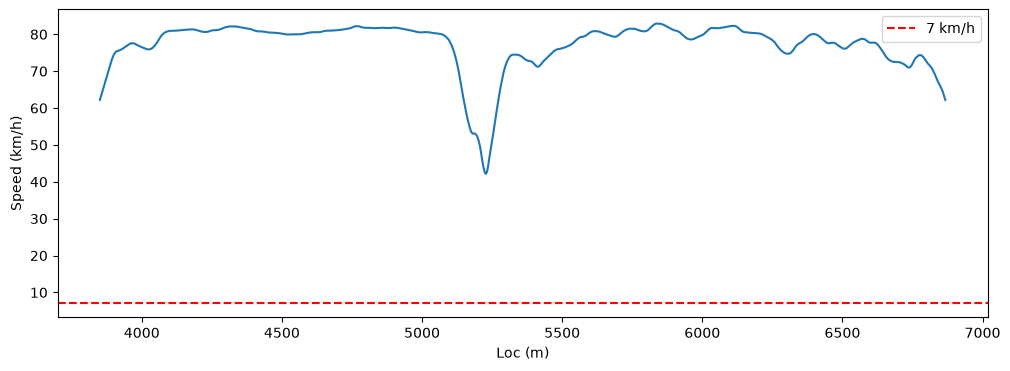

In [7]:
# 1. Where are the 2 empty values?
empty = df.isna()
print("Columns with empty values:", empty.sum()[empty.sum() > 0].to_dict())
print("Row numbers:", df.index[empty.any(axis=1)].tolist(), "out of", len(df))

# 2. How often does the sensor record?
print("Time between rows (ms):", df["Timer(ms)"].diff().median())

# 3. Where is the car slow?
plt.figure(figsize=(12, 4))
plt.plot(df["Loc(m)"], df["Speed_kmh"])
plt.axhline(7, color="red", linestyle="--", label="7 km/h")
plt.xlabel("Loc (m)")
plt.ylabel("Speed (km/h)")
plt.legend()
plt.show()

In [8]:
trimmed = trim_ends(df)

print("Kept Loc:", round(trimmed["Loc(m)"].min()), "-", round(trimmed["Loc(m)"].max()))
print("Rows:", len(df), "->", len(trimmed))
print("muu before:", df["muu"].value_counts().sort_index().to_dict())
print("muu after: ", trimmed["muu"].value_counts().sort_index().to_dict())

Kept Loc: 3856 - 6861
Rows: 56873 -> 56604
muu before: {0: 40569, 1: 11681, 3: 2407, 4: 1130, 5: 1086}
muu after:  {0: 40300, 1: 11681, 3: 2407, 4: 1130, 5: 1086}


In [9]:
# Let's count the number of bumps before and after cleaning.
# To see that trimming the ends of the drive does not remove bumps, 
# we will count the number of bumps in the raw data and in the cleaned data.
def count_bumps(flag):
    return (flag & ~flag.shift(fill_value=False)).sum()

for f in sorted(Path("../dataset").glob("*.txt")):
    raw = pd.read_csv(f, sep="\t", dtype=str)
    raw_posneg = pd.to_numeric(raw["posneg"].str.replace(",", "."))
    clean = load_clean(f)
    print(f"  bumps raw: {count_bumps(raw_posneg > 0.5)}  |  bumps after cleaning: {count_bumps(clean['posneg'] > 0)}")

..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
  bumps raw: 13  |  bumps after cleaning: 13
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
  bumps raw: 13  |  bumps after cleaning: 13
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
  bumps raw: 13  |  bumps after cleaning: 13
..\dataset\Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.txt: 108473 rows
  bumps raw: 7  |  bumps after cleaning: 7
..\dataset\sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.txt: 6426 rows
  bumps raw: 2  |  bumps after cleaning: 2
..\dataset\sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.txt: 7665 rows
  bumps raw: 2  |  bumps after cleaning: 2
..\dataset\sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959.txt: 9222 rows
  bumps raw: 2  |  bumps after cleaning: 2
..\dataset\sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.txt: 18128 rows
  bumps raw: 2  |  bumps after cleaning: 2


In [10]:
for f in sorted(Path("../dataset").glob("*.txt")):
    df = load_clean(f)

    # 1. Where are the empty values?
    empty = df.isna().sum()
    print("  empty columns:", empty[empty > 0].to_dict(),
          "| at rows:", df.index[df.isna().any(axis=1)].tolist(), "of", len(df))

    # 2. How often does the sensor record?
    print("  ms between rows:", df["Timer(ms)"].diff().median())

    # 3. Trimming: does it cut away any labelled rows?
    t = trim_ends(df)
    lost = (df["muu"] != 0).sum() - (t["muu"] != 0).sum()
    print(f"  trimmed: {len(df)} -> {len(t)} rows | labelled rows lost: {lost}")    

..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
  empty columns: {} | at rows: [] of 56873
  ms between rows: 2.5
  trimmed: 56873 -> 56604 rows | labelled rows lost: 0
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
  empty columns: {} | at rows: [] of 75465
  ms between rows: 2.5
  trimmed: 75465 -> 75445 rows | labelled rows lost: 0
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
  empty columns: {} | at rows: [] of 114684
  ms between rows: 2.5
  trimmed: 114684 -> 114678 rows | labelled rows lost: 0
..\dataset\Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.txt: 108473 rows
  empty columns: {} | at rows: [] of 108473
  ms between rows: 2.5
  trimmed: 108473 -> 108455 rows | labelled rows lost: 0
..\dataset\sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.txt: 6426 rows
  empty columns: {} | at rows: [] of 6426
  ms between rows: 2.5
  trimmed: 6426 -> 5819 rows | labelled rows lost: 0
..\dataset\sinetänsalmentie_

In [11]:
# Let's check that there are no empty values left after cleaning.
for f in sorted(Path("../dataset").glob("*.txt")):
    df = load_clean(f)
    print("  empty values left:", df.isna().sum().sum())

..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
  empty values left: 0
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
  empty values left: 0
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
  empty values left: 0
..\dataset\Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.txt: 108473 rows
  empty values left: 0
..\dataset\sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.txt: 6426 rows
  empty values left: 0
..\dataset\sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.txt: 7665 rows
  empty values left: 0
..\dataset\sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959.txt: 9222 rows
  empty values left: 0
..\dataset\sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.txt: 18128 rows
  empty values left: 0


In [15]:
out = Path("data_clean")
out.mkdir(exist_ok=True)

for f in sorted(Path("../dataset").glob("*.txt")):
    df = load_clean(f)
    df.to_csv(out / f"{f.stem}.csv", index=False)

print("Saved:", [p.name for p in out.glob("*.csv")])

..\dataset\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt: 56873 rows
..\dataset\Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.txt: 75465 rows
..\dataset\Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.txt: 114684 rows
..\dataset\Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.txt: 108473 rows
..\dataset\sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.txt: 6426 rows
..\dataset\sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.txt: 7665 rows
..\dataset\sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959.txt: 9222 rows
..\dataset\sinetänsalmentie_Acc1_m795_RDMC_2026-05-06_113156.txt: 18128 rows
Saved: ['Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.csv', 'Iisingintie_Acc1_m801_RDMC_2026-05-06_124454.csv', 'Iisingintie_Acc1_m802_RDMC_2026-05-06_125211.csv', 'Kaittiaisentie_Acc1_RDMC_2026-05-06_132147.csv', 'sinetänsalmentie_Acc1_m792_RDMC_2026-05-06_112539.csv', 'sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.csv', 'sinetänsalmentie_Acc1_m794_RDMC_2026-05-06_112959.csv', 'sinetänsalmentie_Acc1